In [1]:
%pip install pandas numpy openpyxl geopandas shapely matplotlib folium cartopy requests

   ---------------------------------------- 0.0/9.1 MB ? eta -:--:--
   ----------------------- ---------------- 5.2/9.1 MB 27.7 MB/s eta 0:00:01
   ---------------------------------------- 9.1/9.1 MB 31.6 MB/s  0:00:00

   -------------------- ------------------- 2/4 [folium]
   ------------------------------ --------- 3/4 [cartopy]
   ------------------------------ --------- 3/4 [cartopy]
   ------------------------------ --------- 3/4 [cartopy]
   ------------------------------ --------- 3/4 [cartopy]
   ---------------------------------------- 4/4 [cartopy]

Note: you may need to restart the kernel to use updated packages.


Import the libraries

In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
import requests

from shapely.geometry import LineString
from IPython.display import display

print("All libraries imported successfully!")

All libraries imported successfully!


Download the port dataset

In [3]:
ports_url = (
    "https://github.com/magisAR9/JE-Ormuz/"
    "raw/refs/heads/main/PORTS_monde.xlsx"
)

ports = pd.read_excel(ports_url, engine="openpyxl")

In [4]:
print("Dataset dimensions:", ports.shape)

print("\nColumn names:")
print(ports.columns.tolist())

display(ports.head())

Dataset dimensions: (5727, 5)

Column names:
['PortID', 'PortName', 'Country', 'LatitudeDecimal', 'LongitudeDecimal']


,PortID,PortName,Country,LatitudeDecimal,LongitudeDecimal
0,10003,Funafuti,Tuvalu,-8.516666,179.216667
1,10004,Famagusta,Cyprus,35.131917,33.944950
2,10005,Withnell Bay,Australia,-20.584350,116.760383
3,10006,Crinan Canal,United Kingdom,56.091433,-5.556000
4,10008,Porthmadog,United Kingdom,52.923400,-4.128850


Check and clean the port dataset

In [5]:
# Check missing values
print(ports.isnull().sum())

# Check duplicated records
print("Duplicates:", ports.duplicated().sum())

# Check data types
print(ports.dtypes)

PortID              0
PortName            0
Country             0
LatitudeDecimal     0
LongitudeDecimal    0
dtype: int64
Duplicates: 0
PortID                int64
PortName                str
Country                 str
LatitudeDecimal     float64
LongitudeDecimal    float64
dtype: object


In [6]:
ports["LatitudeDecimal"] = pd.to_numeric(
    ports["LatitudeDecimal"], errors="coerce"
)

ports["LongitudeDecimal"] = pd.to_numeric(
    ports["LongitudeDecimal"], errors="coerce"
)

ports = ports.dropna(
    subset=["LatitudeDecimal", "LongitudeDecimal"]
)

ports = ports[
    ports["LatitudeDecimal"].between(-90, 90) &
    ports["LongitudeDecimal"].between(-180, 180)
]

print("Cleaned dataset:", ports.shape)

Cleaned dataset: (5727, 5)


Create your GeoDataFrame

In [7]:
geoports = gpd.GeoDataFrame(
    ports,
    geometry=gpd.points_from_xy(
        ports["LongitudeDecimal"],
        ports["LatitudeDecimal"]
    ),
    crs="EPSG:4326"
)

display(geoports.head())

,PortID,PortName,Country,LatitudeDecimal,LongitudeDecimal,geometry
0,10003,Funafuti,Tuvalu,-8.516666,179.216667,POINT (179.21667 -8.51667)
1,10004,Famagusta,Cyprus,35.131917,33.944950,POINT (33.94495 35.13192)
2,10005,Withnell Bay,Australia,-20.584350,116.760383,POINT (116.76038 -20.58435)
3,10006,Crinan Canal,United Kingdom,56.091433,-5.556000,POINT (-5.556 56.09143)
4,10008,Porthmadog,United Kingdom,52.923400,-4.128850,POINT (-4.12885 52.9234)


first map of the world's ports

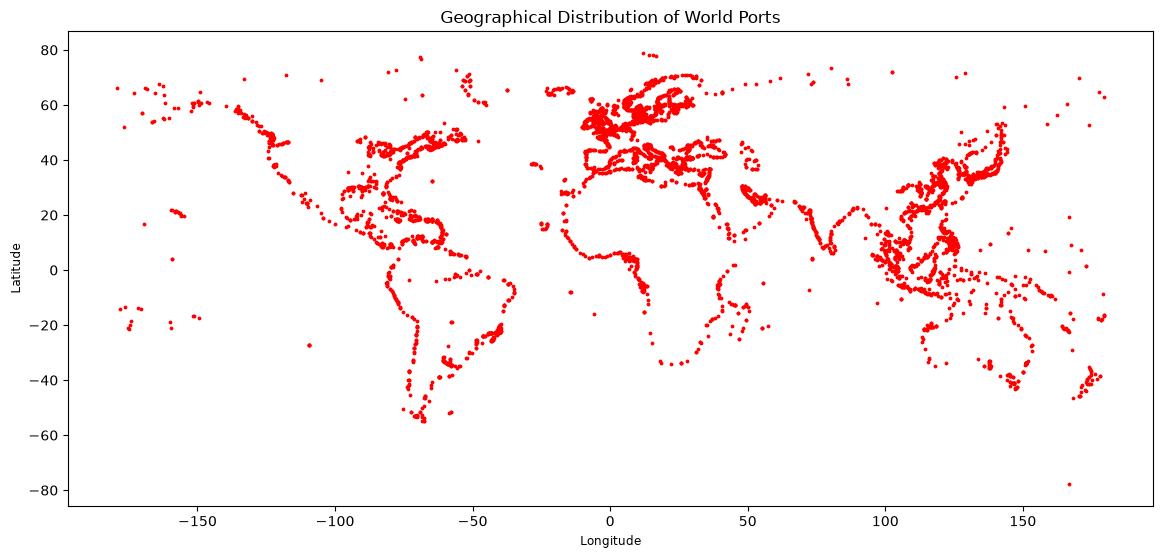

In [8]:
ax = geoports.plot(
    figsize=(14, 8),
    markersize=3,
    color="red"
)

ax.set_title("Geographical Distribution of World Ports")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

Study the ports around Hormuz

Load the Hormuz port dataset

In [10]:
from pathlib import Path

data_folder = Path(r"C:\Users\kolla\OneDrive\Desktop\Msc_GGL\3rd Semister\Geospatial and web development\Project Ormuz\Data")

file_ports = data_folder / "PORTS_monde.xlsx"

file_hormuz = data_folder / "ESCALES PC GNL ET TANKER.xlsx"

file_world = data_folder / "ESCALES_GDS_TANKERS_+55000dwt.xlsx"

In [11]:
for file in [file_ports, file_hormuz, file_world]:
    print(file.name, file.exists())

PORTS_monde.xlsx True
ESCALES PC GNL ET TANKER.xlsx True
ESCALES_GDS_TANKERS_+55000dwt.xlsx True


Read the Excel Data files

In [12]:
ports_W = pd.read_excel(file_ports)

# Read the PORTS sheet
ports_detroit_ormuz = pd.read_excel(
    file_hormuz,
    sheet_name="PORTS"
)

# Read all sheets from the two datasets
xls_hormuz = pd.ExcelFile(file_hormuz)
xls_world = pd.ExcelFile(file_world)

print("Hormuz sheets:", xls_hormuz.sheet_names)
print("World tanker sheets:", xls_world.sheet_names)

Hormuz sheets: ['PC', 'GNL', 'CHEMICAL & OIL TANKER', 'PORTS', 'DESCRIPTION DES CHAMPS']
World tanker sheets: ['Feuil1']


In [13]:
print("World ports:", ports_W.shape)
print("Hormuz ports:", ports_detroit_ormuz.shape)

display(ports_detroit_ormuz.head())

World ports: (5727, 5)
Hormuz ports: (64, 4)


,Port,Country,LatitudeDecimal,LongitudeDecimal
0,Salalah,Oman,16.950300,54.025067
1,Jebel Ali,United Arab Emirates,25.026700,55.032417
2,Bandar Imam Khomeini,Iran,30.419550,49.061217
3,Bandar Abbas,Iran,27.169700,56.281617
4,Assaluyeh,Iran,27.526967,52.536000


Display the 64 Hormuz ports on an interactive map

In [14]:
# Calculate the centre of the map
center_lat = ports_detroit_ormuz["LatitudeDecimal"].mean()
center_lon = ports_detroit_ormuz["LongitudeDecimal"].mean()

# Create map
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=6,
    tiles="OpenStreetMap"
)

# Add port locations
for _, row in ports_detroit_ormuz.iterrows():

    folium.CircleMarker(
        location=[
            row["LatitudeDecimal"],
            row["LongitudeDecimal"]
        ],
        radius=5,
        popup=f'{row["Port"]}, {row["Country"]}',
        color="purple",
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

m

In [15]:
m.save("Hormuz_ports.html")

Analyse the tanker port calls

Understand the tanker datasets

In [16]:
# Inspect the available sheets
for sheet in xls_hormuz.sheet_names:

    df = pd.read_excel(file_hormuz, sheet_name=sheet)

    print("\nSHEET:", sheet)
    print("Dimensions:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


SHEET: PC
Dimensions: (5187, 11)
Columns: ['IMO/LR/IHS No.', 'MMSI', 'Ship Name', 'Operator', 'Port', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Vessel Type', 'Prev Port', 'Voyage Hours']


,IMO/LR/IHS No.,MMSI,Ship Name,Operator,Port,Arrival Time,Sailed Time,Hours in Port,Vessel Type,Prev Port,Voyage Hours
0,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Salalah,2026-01-19 00:11:00,2026-01-19 20:00:00,19.816667,CONTAINER SHIP,Tanger-Mediterranean,528
1,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Jebel Ali,2026-01-22 20:15:00,2026-01-24 01:47:00,29.533333,CONTAINER SHIP,Salalah,72
2,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Salalah,2026-02-04 22:54:00,2026-02-05 18:14:00,19.333333,CONTAINER SHIP,Jawaharlal Nehru Port,69



SHEET: GNL
Dimensions: (931, 13)
Columns: ['IMO/LR/IHS No.', 'Port', 'Port Zone', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']


,IMO/LR/IHS No.,Port,Port Zone,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9443401,Ras Laffan,Ras Laffan,Zeebrugge,538003354.0,AAMIRA,Qatargas Liquefied Gas Co Ltd,LIQUEFIED GAS TANKER,2025-12-04 11:52:00,2025-12-06 04:09:00,40.283333,856,130026
1,9443401,Ras Laffan,Ras Laffan,Incheon,538003354.0,AAMIRA,Qatargas Liquefied Gas Co Ltd,LIQUEFIED GAS TANKER,2026-01-27 09:20:00,2026-01-28 14:12:00,28.866667,753,130026
2,9412062,Ruwais,Ruwais,Jawaharlal Nehru Port,636025577.0,ADMAR,Columbia Shipmanagement Ltd,LIQUEFIED GAS TANKER,2026-01-14 03:02:00,2026-01-14 21:17:00,18.250000,197,26540



SHEET: CHEMICAL & OIL TANKER
Dimensions: (5139, 12)
Columns: ['IMO/LR/IHS No.', 'Port', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']


,IMO/LR/IHS No.,Port,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9411563,Port Rashid,Hamriyah Free Zone Port,372577000.0,A.S. RUBY RED,Aslan Shipping Services,TANKER,2025-12-26 14:00:00,2025-12-28 11:47:00,45.783333,7.0,12885
1,9142502,Khor Fakkan,Durban,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-06 09:52:00,2026-01-07 08:31:00,22.650000,627.0,6649
2,9142502,Khor Fakkan,Karwar,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-25 08:47:00,2026-01-27 09:16:00,48.483333,141.0,6649



SHEET: PORTS
Dimensions: (64, 4)
Columns: ['Port', 'Country', 'LatitudeDecimal', 'LongitudeDecimal']


,Port,Country,LatitudeDecimal,LongitudeDecimal
0,Salalah,Oman,16.95030,54.025067
1,Jebel Ali,United Arab Emirates,25.02670,55.032417
2,Bandar Imam Khomeini,Iran,30.41955,49.061217



SHEET: DESCRIPTION DES CHAMPS
Dimensions: (13, 3)
Columns: ['CHAMP', 'Description ', 'Précisions éventuelles']


,CHAMP,Description,Précisions éventuelles
0,IMO/LR/IHS No.,Numéro d'identification unique du navire attri...,NaN
1,MMSI,Identifiant numérique unique à 9 chiffres attr...,NaN
2,Port,Nom du port dans lequel le navire effectue une...,NaN


In [17]:
# Inspect the available sheets
for sheet in xls_hormuz.sheet_names:

    df = pd.read_excel(file_hormuz, sheet_name=sheet)

    print("\nSHEET:", sheet)
    print("Dimensions:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


SHEET: PC
Dimensions: (5187, 11)
Columns: ['IMO/LR/IHS No.', 'MMSI', 'Ship Name', 'Operator', 'Port', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Vessel Type', 'Prev Port', 'Voyage Hours']


,IMO/LR/IHS No.,MMSI,Ship Name,Operator,Port,Arrival Time,Sailed Time,Hours in Port,Vessel Type,Prev Port,Voyage Hours
0,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Salalah,2026-01-19 00:11:00,2026-01-19 20:00:00,19.816667,CONTAINER SHIP,Tanger-Mediterranean,528
1,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Jebel Ali,2026-01-22 20:15:00,2026-01-24 01:47:00,29.533333,CONTAINER SHIP,Salalah,72
2,9948803,219677000.0,A. P. MOLLER,Maersk A/S,Salalah,2026-02-04 22:54:00,2026-02-05 18:14:00,19.333333,CONTAINER SHIP,Jawaharlal Nehru Port,69



SHEET: GNL
Dimensions: (931, 13)
Columns: ['IMO/LR/IHS No.', 'Port', 'Port Zone', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']


,IMO/LR/IHS No.,Port,Port Zone,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9443401,Ras Laffan,Ras Laffan,Zeebrugge,538003354.0,AAMIRA,Qatargas Liquefied Gas Co Ltd,LIQUEFIED GAS TANKER,2025-12-04 11:52:00,2025-12-06 04:09:00,40.283333,856,130026
1,9443401,Ras Laffan,Ras Laffan,Incheon,538003354.0,AAMIRA,Qatargas Liquefied Gas Co Ltd,LIQUEFIED GAS TANKER,2026-01-27 09:20:00,2026-01-28 14:12:00,28.866667,753,130026
2,9412062,Ruwais,Ruwais,Jawaharlal Nehru Port,636025577.0,ADMAR,Columbia Shipmanagement Ltd,LIQUEFIED GAS TANKER,2026-01-14 03:02:00,2026-01-14 21:17:00,18.250000,197,26540



SHEET: CHEMICAL & OIL TANKER
Dimensions: (5139, 12)
Columns: ['IMO/LR/IHS No.', 'Port', 'Prev Port', 'MMSI', 'Ship Name', 'Operator', 'Vessel Type', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'Voyage Hours', 'DWT']


,IMO/LR/IHS No.,Port,Prev Port,MMSI,Ship Name,Operator,Vessel Type,Arrival Time,Sailed Time,Hours in Port,Voyage Hours,DWT
0,9411563,Port Rashid,Hamriyah Free Zone Port,372577000.0,A.S. RUBY RED,Aslan Shipping Services,TANKER,2025-12-26 14:00:00,2025-12-28 11:47:00,45.783333,7.0,12885
1,9142502,Khor Fakkan,Durban,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-06 09:52:00,2026-01-07 08:31:00,22.650000,627.0,6649
2,9142502,Khor Fakkan,Karwar,620999994.0,A3R H,A3R H Shipping Inc,TANKER,2026-01-25 08:47:00,2026-01-27 09:16:00,48.483333,141.0,6649



SHEET: PORTS
Dimensions: (64, 4)
Columns: ['Port', 'Country', 'LatitudeDecimal', 'LongitudeDecimal']


,Port,Country,LatitudeDecimal,LongitudeDecimal
0,Salalah,Oman,16.95030,54.025067
1,Jebel Ali,United Arab Emirates,25.02670,55.032417
2,Bandar Imam Khomeini,Iran,30.41955,49.061217



SHEET: DESCRIPTION DES CHAMPS
Dimensions: (13, 3)
Columns: ['CHAMP', 'Description ', 'Précisions éventuelles']


,CHAMP,Description,Précisions éventuelles
0,IMO/LR/IHS No.,Numéro d'identification unique du navire attri...,NaN
1,MMSI,Identifiant numérique unique à 9 chiffres attr...,NaN
2,Port,Nom du port dans lequel le navire effectue une...,NaN


In [18]:
for sheet in xls_world.sheet_names:

    df = pd.read_excel(file_world, sheet_name=sheet)

    print("\nSHEET:", sheet)
    print("Dimensions:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


SHEET: Feuil1
Dimensions: (30753, 13)
Columns: ['IMO/LR/IHS No.', 'MMSI', 'Ship Name', 'Operator', 'Port', 'Port Zone', 'Arrival Time', 'Sailed Time', 'Hours in Port', 'DWT', 'Arrival Draught', 'Departure Draught', 'Voyage Hours']


,IMO/LR/IHS No.,MMSI,Ship Name,Operator,Port,Port Zone,Arrival Time,Sailed Time,Hours in Port,DWT,Arrival Draught,Departure Draught,Voyage Hours
0,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,FPSO 'Ichthys Venturer',FPSO 'Ichthys Venturer',2025-12-22 07:11:00,2025-12-23 22:11:00,39.000000,114066,8.5,8.5,513.0
1,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Singapore,Jurong,2025-12-29 08:46:00,2025-12-30 16:47:00,32.016667,114066,12.0,8.5,130.0
2,9838589,636020999.0,A LEOPARD,CSSA Chartering & Shipping,Sikka,Jamnagar Terminal SPM No 5,2026-01-15 03:16:00,2026-01-16 04:32:00,25.266667,114066,8.5,14.7,371.0


Prepare the port-call data

In [21]:
calls_hormuz = pd.read_excel(
    file_hormuz,
    sheet_name="Hormuz ports"
)

calls_world = pd.read_excel(
    file_world,
    sheet_name="Hormuz ports"
)

ValueError: Worksheet named 'Hormuz ports' not found